[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch53_LabCh53_Sound_By_Hand.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 53: Sound: Speech and Audio** (Part XI: Imagining in Depth).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=53](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=53)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch53 - Sound by hand
## Make sounds from numbers, turn them into pictures, and read a string of telephone keys with CTC

This lab goes with **Chapter 53** of *The Why Book of Deep Learning, Part 2*.

There are no audio files here. Every sound is made with NumPy: pure tones, a chord, a chirp, and the tones
a telephone keypad sends when you press a key (each key is two sine waves added together). You will turn
those sounds into spectrograms by hand, see what the window length trades away, squeeze the frequency axis
into mel bands, and then train two small networks: one that names a single key buried in noise, and one that
reads a whole string of keys of unknown length and timing, trained with **CTC** loss.

| The miniature | value |
|---|---|
| sampling rate | 8,000 samples a second (telephone quality) |
| spectrogram | 25 ms frames (200 samples) every 10 ms (80 samples), 256-point FFT, 129 frequency bins |
| features | log of the energy in 40 mel-spaced bands |
| task 1 | one key in a quarter-second clip, in noise: a CNN with 14,444 parameters |
| task 2 | 1 to 6 keys in a 1.2-second clip, in noise: a convolutional recogniser with 67,277 parameters and CTC |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Say what a sampling rate can and cannot hold, and show aliasing | Steps 2 and 3 |
| Explain why a raw waveform is a poor input and a spectrogram a good one | Steps 4 and 5 |
| Compute a spectrogram by hand: frame, window, FFT, magnitude, log | Step 6 |
| Choose a window length knowing what it costs | Step 7 |
| Build a mel filter bank and count what it saves | Step 8 |
| Train a CNN on spectrograms and read its mistakes | Steps 9 to 13 |
| Break a working recogniser four ways at serving time, and test a flip | Step 14 |
| Compute the CTC loss of a tiny example by listing every alignment | Step 16 |
| Train with CTC, decode greedily, read the alignments and score with edit distance | Steps 17 to 21 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about two to three minutes on a laptop CPU. Most of it is Step 18 (the CTC training run).
> No GPU is needed and nothing is downloaded.

> **Honest scale:** this is a miniature. Twelve keypad tones are to speech what a traffic light is to a
> painting: two clean frequencies per symbol, no accents, no words. The numbers printed here describe this
> toy and say nothing about what a speech recogniser scores. What carries over is the pipeline (waveform,
> frames, log-mel picture, network, CTC, edit distance) and the kinds of mistake.

---
## Step 1 - Imports and one seed

In [1]:
import os, time, itertools
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 53
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - A sound is a list of numbers

A microphone measures air pressure. A converter reads that measurement at a fixed rate, the **sampling
rate**, and writes down one number each time. That list is all a computer ever has of a sound.

We use 8,000 samples a second, the rate of the classic telephone network. Speech models usually use 16,000
and music 44,100 or 48,000.

**Predict:** how many numbers is 30 seconds of speech at 16,000 samples a second? How many is a
three-minute song at 44,100, in stereo?

half a second of a 440 Hz tone: (4000,) float64 | first six samples: [0.    0.339 0.637 0.861 0.982 0.988]
one cycle of 440 Hz takes 18.2 samples at 8,000 samples a second
30 s of speech at 16 kHz      :    480,000 numbers
30 s at our 8 kHz             :    240,000 numbers
3 min of stereo at 44.1 kHz   : 15,876,000 numbers


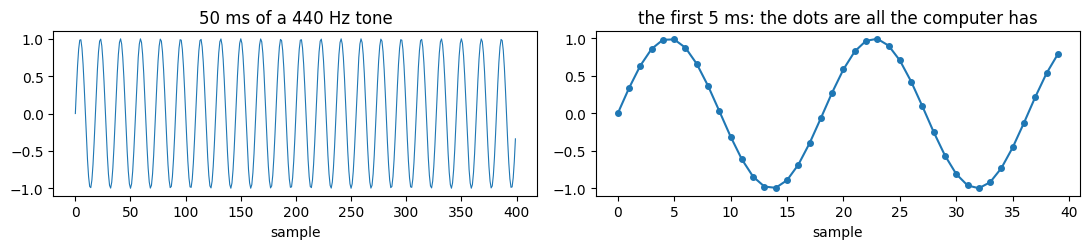

In [2]:
SR = 8000                                       # samples per second, everywhere in this lab

def tone(freq, seconds, sr=SR, phase=0.0):
    """A pure sine wave: `freq` cycles a second, as a 1-D array of seconds * sr numbers."""
    t = np.arange(int(round(seconds * sr))) / sr
    return np.sin(2 * np.pi * freq * t + phase)

a440 = tone(440, 0.5)
print("half a second of a 440 Hz tone:", a440.shape, a440.dtype, "| first six samples:", a440[:6])
print(f"one cycle of 440 Hz takes {SR / 440:.1f} samples at {SR:,} samples a second")
print(f"30 s of speech at 16 kHz      : {30 * 16000:>10,} numbers")
print(f"30 s at our 8 kHz             : {30 * SR:>10,} numbers")
print(f"3 min of stereo at 44.1 kHz   : {180 * 44100 * 2:>10,} numbers")

fig, ax = plt.subplots(1, 2, figsize=(11, 2.6))
ax[0].plot(a440[:400], lw=0.8); ax[0].set_title("50 ms of a 440 Hz tone"); ax[0].set_xlabel("sample")
ax[1].plot(a440[:40], "o-", ms=4); ax[1].set_title("the first 5 ms: the dots are all the computer has")
ax[1].set_xlabel("sample"); plt.tight_layout(); plt.show()

### Why we see this

Thirty seconds of speech is 480,000 numbers, and none of them means anything on its own: one sample is the
pressure at one instant. Compare a sentence of perhaps 80 words. A model that reads raw samples must find
those 80 words in a sequence 6,000 times longer.

---
## Step 3 - What a sampling rate cannot hold

To record a wave you need at least two samples per cycle: one for the up and one for the down. So a rate
of 8,000 can hold frequencies up to 4,000 Hz and no higher. That limit, half the sampling rate, is the
**Nyquist frequency**.

**Predict:** we sample a 3,000 Hz tone and a 5,000 Hz tone at 8,000 samples a second, then ask the Fourier
transform which frequency is strongest in each. What does it say for the 5,000 Hz tone?

In [3]:
def strongest(x, sr=SR):
    """The frequency with the most energy in the whole clip, from one FFT."""
    mag = np.abs(np.fft.rfft(x * np.hanning(len(x))))
    return np.fft.rfftfreq(len(x), 1 / sr)[mag.argmax()]

for f in [1000, 3000, 3900, 4100, 5000, 7000]:
    print(f"a {f:>5,} Hz tone sampled at {SR:,} Hz looks like {strongest(tone(f, 0.25)):>6,.0f} Hz")

n = np.arange(12)
s3, s5 = np.sin(2 * np.pi * 3000 * n / SR), np.sin(2 * np.pi * 5000 * n / SR)
print("\nsamples of the 3,000 Hz tone:", s3.round(2))
print("samples of the 5,000 Hz tone:", s5.round(2))
print("largest difference between the 5,000 Hz samples and the 3,000 Hz samples turned upside down:",
      f"{np.abs(s5 + s3).max():.1e}")

a 1,000 Hz tone sampled at 8,000 Hz looks like  1,000 Hz
a 3,000 Hz tone sampled at 8,000 Hz looks like  3,000 Hz
a 3,900 Hz tone sampled at 8,000 Hz looks like  3,900 Hz
a 4,100 Hz tone sampled at 8,000 Hz looks like  3,900 Hz
a 5,000 Hz tone sampled at 8,000 Hz looks like  3,000 Hz
a 7,000 Hz tone sampled at 8,000 Hz looks like  1,000 Hz

samples of the 3,000 Hz tone: [ 0.    0.71 -1.    0.71  0.   -0.71  1.   -0.71 -0.    0.71 -1.    0.71]
samples of the 5,000 Hz tone: [ 0.   -0.71  1.   -0.71  0.    0.71 -1.    0.71 -0.   -0.71  1.   -0.71]
largest difference between the 5,000 Hz samples and the 3,000 Hz samples turned upside down: 2.0e-15


### Why we see this

Above 4,000 Hz the samples of a tone are **exactly** the samples of a lower tone: 5,000 Hz gives the same
list as 3,000 Hz (upside down), and 7,000 Hz the same as 1,000 Hz. The frequency folds back around the
Nyquist frequency. This is **aliasing**, and it cannot be undone afterwards, because the two lists are
identical. Real recorders remove everything above the limit with a filter *before* sampling. If you
downsample audio yourself by keeping every second sample, you must filter first too.

---
## Step 4 - Why not feed the raw wave to a network?

Length is one problem. Here is the other. Take a 697 Hz tone and the same tone starting 0.75 milliseconds
later (6 samples). To your ear they are the same sound.

**Predict:** what is the correlation between the two lists of samples: near +1, near 0, or near -1? And
between the sizes of their Fourier coefficients?

shift: 6 samples = 0.75 ms = 0.52 of a cycle at 697 Hz
correlation of the raw samples       : -0.990
correlation of the FFT magnitudes    : +1.000


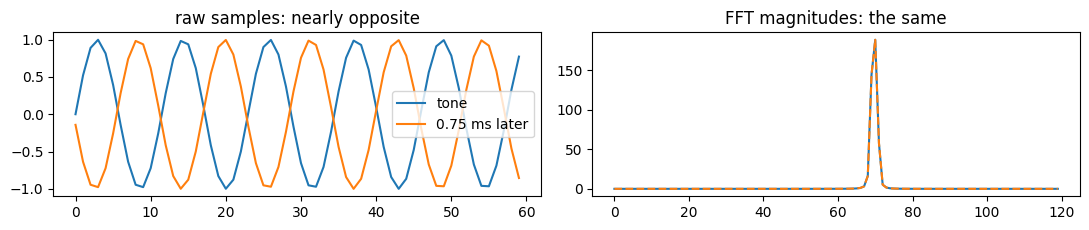

In [4]:
x0 = tone(697, 0.1)
x1 = tone(697, 0.1 + 6 / SR)[6:]                # the same tone, 6 samples (0.75 ms) later
corr = lambda a, b: float(np.corrcoef(a, b)[0, 1])
print(f"shift: 6 samples = {1000 * 6 / SR:.2f} ms = {697 * 6 / SR:.2f} of a cycle at 697 Hz")
print(f"correlation of the raw samples       : {corr(x0, x1):+.3f}")
m0, m1 = np.abs(np.fft.rfft(x0 * np.hanning(len(x0)))), np.abs(np.fft.rfft(x1 * np.hanning(len(x1))))
print(f"correlation of the FFT magnitudes    : {corr(m0, m1):+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 2.4))
ax[0].plot(x0[:60], label="tone"); ax[0].plot(x1[:60], label="0.75 ms later"); ax[0].legend()
ax[0].set_title("raw samples: nearly opposite")
ax[1].plot(m0[:120]); ax[1].plot(m1[:120], "--"); ax[1].set_title("FFT magnitudes: the same")
plt.tight_layout(); plt.show()

### Why we see this

Six samples is about half a cycle of this tone, so every sample has changed sign: the two lists are close
to opposites, and a network looking at raw samples would see two inputs that could hardly differ more. The
Fourier transform splits each frequency into a **size** (how much of it there is) and a **phase** (where in
its cycle it starts). The shift moved the phase and left the size alone. Hearing mostly follows the sizes.
So the first move of nearly every audio system is to keep the sizes and drop the phases.

---
## Step 5 - One FFT knows what, and has no idea when

Two test sounds. A **chord**: three tones at once (440, 554 and 659 Hz, an A major triad). A **chirp**: one
tone that slides from 300 Hz up to 3,000 Hz over a second.

**Predict:** the FFT of the whole chord shows three sharp peaks. What does the FFT of the whole chirp show?

the three strongest frequencies in the chord: [440. 554. 659.] Hz
chirp: 2,689 of 4,001 frequencies are above half the largest value, from 306 to 2994 Hz
the chirp played backwards has the same FFT magnitudes: largest difference 7.1e-14


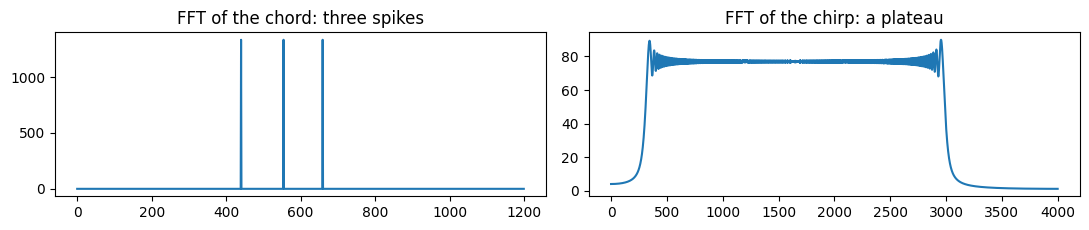

In [5]:
def chirp(f0, f1, seconds, sr=SR):
    """A tone whose frequency slides in a straight line from f0 to f1."""
    t = np.arange(int(seconds * sr)) / sr
    return np.sin(2 * np.pi * (f0 * t + (f1 - f0) * t ** 2 / (2 * seconds)))

chord = (tone(440, 1.0) + tone(554, 1.0) + tone(659, 1.0)) / 3
sweep = chirp(300, 3000, 1.0)
freqs = np.fft.rfftfreq(SR, 1 / SR)
M_chord, M_sweep = np.abs(np.fft.rfft(chord)), np.abs(np.fft.rfft(sweep))
top = np.sort(freqs[np.argsort(M_chord)[-3:]])
print("the three strongest frequencies in the chord:", top, "Hz")
busy = (M_sweep > 0.5 * M_sweep.max()).sum()
print(f"chirp: {busy:,} of {len(freqs):,} frequencies are above half the largest value, "
      f"from {freqs[M_sweep > 0.5 * M_sweep.max()].min():.0f} to {freqs[M_sweep > 0.5 * M_sweep.max()].max():.0f} Hz")
print(f"the chirp played backwards has the same FFT magnitudes: largest difference "
      f"{np.abs(np.abs(np.fft.rfft(sweep[::-1])) - M_sweep).max():.1e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 2.4))
ax[0].plot(freqs[:1200], M_chord[:1200]); ax[0].set_title("FFT of the chord: three spikes")
ax[1].plot(freqs, M_sweep); ax[1].set_title("FFT of the chirp: a plateau"); plt.tight_layout(); plt.show()

### Why we see this

One FFT over the whole clip says how much of each frequency there was **in total**. For the chirp that is
"a bit of everything from 300 to 3,000 Hz". Rising or falling? The sizes cannot say: the chirp played
backwards gives the same answer. (The order is hidden in the phases we decided to drop.) Speech is all
change, so one FFT is useless for it. The cure is to take many short FFTs, one after another.

---
## Step 6 - The spectrogram, by hand

Five moves:

1. **Frame.** Cut the wave into short pieces that overlap: 200 samples (25 ms) long, a new one every 80
   samples (10 ms).
2. **Window.** Multiply each piece by a smooth hump (a Hann window) so that it fades in and out.
3. **FFT** each piece (padded with zeros to 256 points, which gives 129 frequencies from 0 to 4,000 Hz).
4. **Magnitude.** Keep the sizes, drop the phases.
5. **Log.** Take the logarithm, because hearing compares loudness by ratio.

Stack the results side by side and you have a picture: time across, frequency up.

**Predict:** how many frames does a one-second clip (8,000 samples) give? And what shape is the picture?

wave (8000,) -> frames (98, 200) -> spectrogram (98, 129)
each frequency bin is 31.25 Hz wide; bin k is the frequency k x 31.25 Hz
strongest frequency in frames 0, 24, 48, 72, 96: ['344 Hz', '969 Hz', '1625 Hz', '2281 Hz', '2938 Hz']
no window (a hard cut)  : 1.937% of the tone's energy appears more than 200 Hz away from 697 Hz
Hann window             : 0.000% of the tone's energy appears more than 200 Hz away from 697 Hz

loud tone 46.72, quiet tone 0.4976: the quiet one is 1.1% of the loud one; after the log they are 3.84 and -0.70


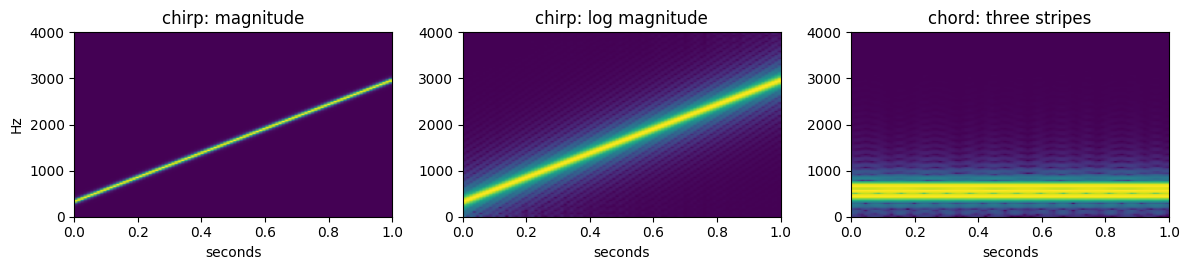

In [6]:
FRAME, HOP, NFFT = 200, 80, 256                 # 25 ms, 10 ms, and the FFT length

def frames(x, frame=FRAME, hop=HOP):
    """Cut the last axis of x into overlapping frames. (..., n) -> (..., n_frames, frame)."""
    n_frames = 1 + (x.shape[-1] - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(n_frames)[:, None]
    return x[..., idx]

def spectrogram(x, frame=FRAME, hop=HOP, nfft=NFFT, window=True):
    """Magnitude spectrogram: (..., n) -> (..., n_frames, nfft // 2 + 1)."""
    f = frames(x, frame, hop)
    if window:
        f = f * np.hanning(frame)
    return np.abs(np.fft.rfft(f, nfft, axis=-1))

fr = frames(sweep)
S = spectrogram(sweep)
assert fr.shape == (1 + (8000 - 200) // 80, 200) == (98, 200)
assert S.shape == (98, NFFT // 2 + 1) == (98, 129)
print("wave", sweep.shape, "-> frames", fr.shape, "-> spectrogram", S.shape)
print(f"each frequency bin is {SR / NFFT:.2f} Hz wide; bin k is the frequency k x {SR / NFFT:.2f} Hz")
print("strongest frequency in frames 0, 24, 48, 72, 96:",
      [f"{S[i].argmax() * SR / NFFT:.0f} Hz" for i in (0, 24, 48, 72, 96)])

# the window: how much of a pure tone's energy lands away from its own frequency?
t697 = tone(697, FRAME / SR)
for name, w in [("no window (a hard cut)", np.ones(FRAME)), ("Hann window", np.hanning(FRAME))]:
    P = np.abs(np.fft.rfft(t697 * w, 4096)) ** 2
    f4 = np.fft.rfftfreq(4096, 1 / SR)
    far = P[np.abs(f4 - 697) > 200].sum() / P.sum()
    print(f"{name:<24}: {100 * far:.3f}% of the tone's energy appears more than 200 Hz away from 697 Hz")

# the log: a loud tone and one 100 times smaller in amplitude
both = tone(700, 0.25) + 0.01 * tone(2500, 0.25)
Sb = spectrogram(both).mean(axis=0)
loud, quiet = Sb[round(700 * NFFT / SR)], Sb[round(2500 * NFFT / SR)]
print(f"\nloud tone {loud:.2f}, quiet tone {quiet:.4f}: the quiet one is {100 * quiet / loud:.1f}% of the loud one;"
      f" after the log they are {np.log(loud):.2f} and {np.log(quiet):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
ax[0].imshow(S.T, origin="lower", aspect="auto", extent=[0, 1, 0, 4000]); ax[0].set_title("chirp: magnitude")
ax[1].imshow(np.log(S.T + 1e-3), origin="lower", aspect="auto", extent=[0, 1, 0, 4000]); ax[1].set_title("chirp: log magnitude")
ax[2].imshow(np.log(spectrogram(chord).T + 1e-3), origin="lower", aspect="auto", extent=[0, 1, 0, 4000]); ax[2].set_title("chord: three stripes")
for a in ax: a.set_xlabel("seconds")
ax[0].set_ylabel("Hz"); plt.tight_layout(); plt.show()

### Why we see this

The chirp is now a rising line: the picture says what **and** when. The chord is three level stripes.

The window matters more than it looks. A frame cut out with scissors starts and stops abruptly, and an
abrupt edge contains every frequency, so a pure tone leaks energy all over the spectrum. Fading the frame in
and out removes nearly all of that leak, at the price of a slightly fatter peak.

The log is not decoration. Without it the quiet tone is 1% of the loud one and a network barely sees it;
with it the two are a few units apart. The log also turns "twice as loud" into "add a constant", which
has a consequence of its own in Step 14.

---
## Step 7 - The window length: sharp in time or sharp in frequency

A test sound with two things that are hard to tell apart. Two **tones** only 73 Hz apart (697 and 770 Hz,
two rows of the telephone keypad) sounding together. And two **clicks** only 6 ms apart.

We make three spectrograms of it, with frames of 8 ms, 25 ms and 64 ms, and count what each can separate.

**Predict:** which window shows the two tones as two stripes? Which shows the two clicks as two clicks?
Does any show both?

         frame  tones seen  clicks seen
  64 =    8 ms           1            2
 200 =   25 ms           2            1
 512 =   64 ms           2            1


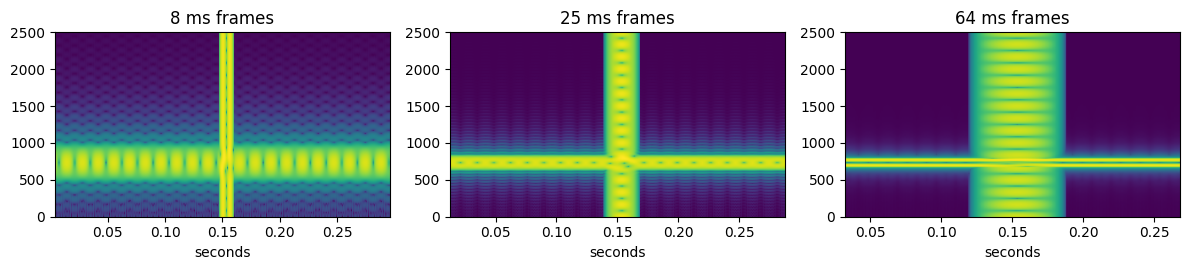

In [7]:
def count_peaks(v, floor=0.5):
    """Number of separate bumps in a curve: local maxima of at least `floor` times the largest value."""
    v = np.asarray(v)
    return int(((v[1:-1] > v[:-2]) & (v[1:-1] >= v[2:]) & (v[1:-1] >= floor * v.max())).sum())

two = tone(697, 0.3) + tone(770, 0.3)
two[1200] += 40.0; two[1248] += 40.0            # two clicks, 48 samples = 6 ms apart
BIG = 2048                                      # plenty of FFT points for every window, so the bins are not the limit
f_big = np.fft.rfftfreq(BIG, 1 / SR)
print(f"{'frame':>14} {'tones seen':>11} {'clicks seen':>12}")
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
trade = {}
for k, win in enumerate([64, 200, 512]):
    Sw = spectrogram(two, frame=win, hop=8, nfft=BIG)
    centre = (win / 2 + 8 * np.arange(len(Sw))) / SR
    calm = Sw[centre < 0.10].mean(axis=0)                       # frames well before the clicks
    n_tones = count_peaks(calm[(f_big > 500) & (f_big < 1000)])
    n_clicks = count_peaks((Sw[:, f_big > 2000] ** 2).sum(axis=1))     # only the clicks have energy up there
    trade[win] = (n_tones, n_clicks)
    print(f"{win:>4} = {1000 * win / SR:>4.0f} ms {n_tones:>11} {n_clicks:>12}")
    ax[k].imshow(np.log(Sw.T + 1e-2), origin="lower", aspect="auto", extent=[centre[0], centre[-1], 0, 4000])
    ax[k].set_ylim(0, 2500); ax[k].set_title(f"{1000 * win / SR:.0f} ms frames"); ax[k].set_xlabel("seconds")
plt.tight_layout(); plt.show()

### Why we see this

No window shows both. To tell 697 Hz from 770 Hz you must watch long enough for the two waves to drift
apart: they differ by 73 cycles a second, so they slip one whole cycle against each other every
1/73 s = 13.7 ms, and a frame has to be longer than that. But a frame that long has swallowed both clicks,
which are only 6 ms apart. Short frames place the clicks and smear the tones into one band. The blur in
time multiplied by the blur in frequency cannot go below a fixed constant. It is the same mathematics as
the uncertainty principle in physics, and no cleverer algorithm removes it. (Adding FFT points does not
help: every window here used 2,048.)

Speech systems settle on about 25 ms: long enough to resolve the pitch structure of a voice, short enough
that the mouth has barely moved.

---
## Step 8 - Mel bands: fewer, wider numbers where hearing is coarse

Hearing tells 500 Hz from 600 Hz easily and 3,500 Hz from 3,600 Hz hardly at all. The **mel scale** is a
warped frequency axis on which equal steps sound like equal steps: roughly straight below 1,000 Hz and
logarithmic above. A **mel filter bank** is a set of triangular bands evenly spaced on that warped axis,
so they are narrow at the bottom and wide at the top. Each band adds up the energy of the FFT bins under it.

We use 40 bands. Speech systems commonly use 80.

**Predict:** the filter bank is a matrix. What is its shape? And for 30 seconds of speech at 16 kHz with
25 ms frames every 10 ms and 80 bands: how many frames, and how many numbers in total, against 480,000
samples?

filter bank (40, 129) | 4,000 Hz is 2146 mels
band  0:      0 to     68 Hz (width   68 Hz)
band 19:    992 to   1156 Hz (width  165 Hz)
band 39:   3583 to   4000 Hz (width  417 Hz)

the chirp: (8000,) -> (98, 40)
30 s at 16 kHz: 480,000 samples -> 3,000 frames x 80 bands = 240,000 numbers
   numbers: 2 times fewer | steps in the sequence: 160 times fewer


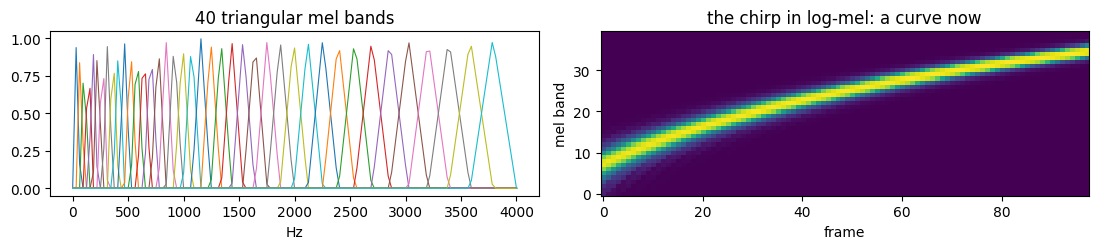

In [8]:
N_MELS = 40
hz_to_mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
mel_to_hz = lambda m: 700.0 * (10.0 ** (m / 2595.0) - 1.0)

def mel_bank(n_mels=N_MELS, nfft=NFFT, sr=SR):
    """Triangular bands, evenly spaced in mels from 0 Hz to sr / 2. Shape (n_mels, nfft // 2 + 1)."""
    edges = mel_to_hz(np.linspace(0.0, hz_to_mel(sr / 2), n_mels + 2))
    f = np.arange(nfft // 2 + 1) * sr / nfft
    bank = np.zeros((n_mels, len(f)))
    for i in range(n_mels):
        lo, mid, hi = edges[i:i + 3]
        bank[i] = np.clip(np.minimum((f - lo) / (mid - lo), (hi - f) / (hi - mid)), 0.0, None)
    return bank, edges

BANK, EDGES = mel_bank()
assert BANK.shape == (40, 129) and (BANK.sum(axis=1) > 0).all()
print("filter bank", BANK.shape, "| 4,000 Hz is", f"{hz_to_mel(4000):.0f} mels")
print(f"band  0: {EDGES[0]:6.0f} to {EDGES[2]:6.0f} Hz (width {EDGES[2] - EDGES[0]:4.0f} Hz)")
print(f"band 19: {EDGES[19]:6.0f} to {EDGES[21]:6.0f} Hz (width {EDGES[21] - EDGES[19]:4.0f} Hz)")
print(f"band 39: {EDGES[39]:6.0f} to {EDGES[41]:6.0f} Hz (width {EDGES[41] - EDGES[39]:4.0f} Hz)")

def log_mel(x):
    """Wave (..., n) -> log-mel picture (..., n_frames, 40): the five moves of Step 6, then the bands."""
    power = spectrogram(x) ** 2
    return np.log(power @ BANK.T + 1e-3).astype("float32")

print("\nthe chirp:", sweep.shape, "->", log_mel(sweep).shape)
n30, f30 = 30 * 16000, 30 * 16000 // 160
print(f"30 s at 16 kHz: {n30:,} samples -> {f30:,} frames x 80 bands = {f30 * 80:,} numbers")
print(f"   numbers: {n30 / (f30 * 80):.0f} times fewer | steps in the sequence: {n30 // f30} times fewer")

fig, ax = plt.subplots(1, 2, figsize=(11, 2.6))
for row in BANK: ax[0].plot(np.arange(129) * SR / NFFT, row, lw=0.8)
ax[0].set_title("40 triangular mel bands"); ax[0].set_xlabel("Hz")
ax[1].imshow(log_mel(sweep).T, origin="lower", aspect="auto"); ax[1].set_title("the chirp in log-mel: a curve now")
ax[1].set_xlabel("frame"); ax[1].set_ylabel("mel band"); plt.tight_layout(); plt.show()

### Why we see this

Read the count carefully, because it is usually misquoted. 480,000 samples become 3,000 × 80 = 240,000
numbers: only **two** times fewer. The saving is somewhere else. The **sequence** is 160 times shorter
(3,000 steps instead of 480,000), and each step is now a column of 80 numbers that mean something: how much
energy near each pitch. Attention cost grows with the square of the length (Chapter 22), so 160 times
shorter is what makes a transformer over audio affordable.

The straight chirp became a curve, because the mel axis is stretched at the bottom and squeezed at the top.

---
## Step 9 - The telephone keypad: two tones per key

Press a key on a tone-dialling telephone and it sends two sine waves at once: one for the key's **row**
and one for its **column** (dual-tone multi-frequency signalling, DTMF).

| | 1209 Hz | 1336 Hz | 1477 Hz |
|---|---|---|---|
| **697 Hz** | 1 | 2 | 3 |
| **770 Hz** | 4 | 5 | 6 |
| **852 Hz** | 7 | 8 | 9 |
| **941 Hz** | * | 0 | # |

Our generator adds what a real line adds: each frequency is off by up to 1.5%, the two tones differ in
level by up to 4 dB, the phases are random, and the tone fades in and out over 2 ms.

**Predict:** the rows are 73, 82 and 89 Hz apart, and our FFT bins are 31.25 Hz wide. For key 5
(770 + 1336 Hz), which two bins will be the strongest? Will they be exactly 770 and 1336?

key 1: 697 + 1209 Hz   key 2: 697 + 1336 Hz   key 3: 697 + 1477 Hz
key 4: 770 + 1209 Hz   key 5: 770 + 1336 Hz   key 6: 770 + 1477 Hz
key 7: 852 + 1209 Hz   key 8: 852 + 1336 Hz   key 9: 852 + 1477 Hz
key *: 941 + 1209 Hz   key 0: 941 + 1336 Hz   key #: 941 + 1477 Hz

key 5, strongest bin below 1,000 Hz: 750 Hz | above: 1344 Hz
multiples of the low tones: [1394, 1540, 1704, 1882] [2091, 2310, 2556, 2823]


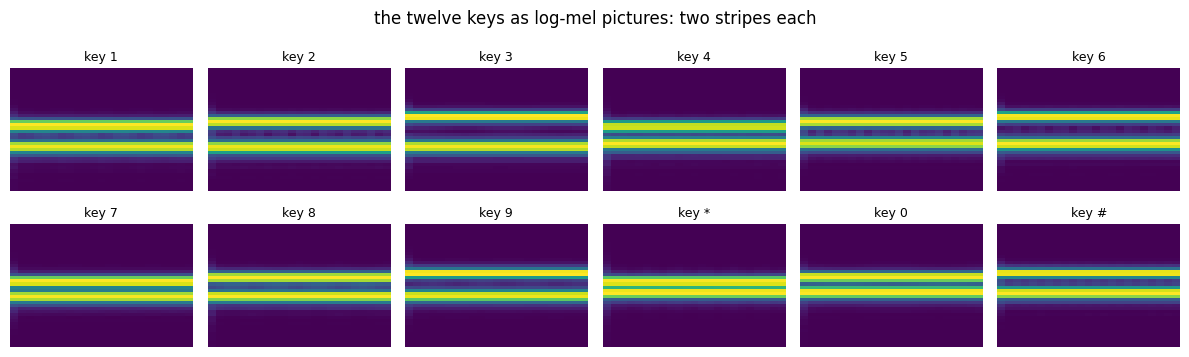

In [9]:
LOW, HIGH = [697, 770, 852, 941], [1209, 1336, 1477]
KEYS = "123456789*0#"                           # key number k is KEYS[k]; row k // 3, column k % 3

def key_freqs(k):
    return LOW[k // 3], HIGH[k % 3]

def key_tone(k, n, rng, sr=SR):
    """n samples of key k as a real line would carry it, scaled to power 1."""
    f_low, f_high = key_freqs(k)
    f_low *= 1 + rng.uniform(-0.015, 0.015); f_high *= 1 + rng.uniform(-0.015, 0.015)
    t = np.arange(n) / sr
    level = 10 ** (rng.uniform(-4, 4) / 20)                     # the high tone is up to 4 dB louder or quieter
    x = np.sin(2 * np.pi * f_low * t + rng.uniform(0, 2 * np.pi)) \
        + level * np.sin(2 * np.pi * f_high * t + rng.uniform(0, 2 * np.pi))
    ramp = 16
    x[:ramp] *= np.linspace(0, 1, ramp); x[-ramp:] *= np.linspace(1, 0, ramp)
    return x / np.sqrt(np.mean(x ** 2))

rng = np.random.default_rng(SEED)
for k in range(12):
    print(f"key {KEYS[k]}: {key_freqs(k)[0]} + {key_freqs(k)[1]} Hz", end="   " if k % 3 < 2 else "\n")
five = spectrogram(key_tone(4, 800, rng)).mean(axis=0)
low_bin = five[:32].argmax(); high_bin = 32 + five[32:].argmax()
print(f"\nkey 5, strongest bin below 1,000 Hz: {low_bin * SR / NFFT:.0f} Hz | above: {high_bin * SR / NFFT:.0f} Hz")
print("multiples of the low tones:", [2 * f for f in LOW], [3 * f for f in LOW])

fig, ax = plt.subplots(2, 6, figsize=(12, 3.6))
for k in range(12):
    ax[k // 6, k % 6].imshow(log_mel(key_tone(k, 2000, rng)).T, origin="lower", aspect="auto")
    ax[k // 6, k % 6].set_title(f"key {KEYS[k]}", fontsize=9); ax[k // 6, k % 6].axis("off")
plt.suptitle("the twelve keys as log-mel pictures: two stripes each"); plt.tight_layout(); plt.show()

### Why we see this

The strongest bins are the ones nearest the true tones: the FFT can only answer in steps of 31.25 Hz, and
the line itself is allowed to be 1.5% off. That is still plenty to tell the rows apart, because only one
row tone sounds at a time: locating one tone alone is much easier than separating two that sound together
(Step 7). Look at the printed multiples too. Twice or three times a row tone never lands on a column
tone, so a distorted line, which adds such multiples, cannot turn one key into another.

---
## Step 10 - Task 1 data: one key, somewhere in a quarter of a second, in noise

Each clip is 2,000 samples (0.25 s). The key sounds for 40 to 100 ms, starting anywhere. Then we add white
noise. The **signal-to-noise ratio** (SNR) compares the power of the tone while it sounds with the power of
the noise, in decibels: 0 dB means equal power, -10 dB means the noise is 10 times stronger.

Training clips have an SNR drawn between -15 and 0 dB.

**Predict:** at -10 dB the noise has ten times the tone's power, and in the waveform the tone is
invisible. In the spectrogram, will the tone's two bins be weaker or stronger than a typical noise bin?

made 6,000 clips in 3.5s | waves (6000, 2000) -> pictures (6000, 23, 40, 1)
numbers per clip: 2,000 samples -> 23 x 40 = 920
at -10 dB: the tone's bin is 11 times a typical noise bin (10 dB above it)


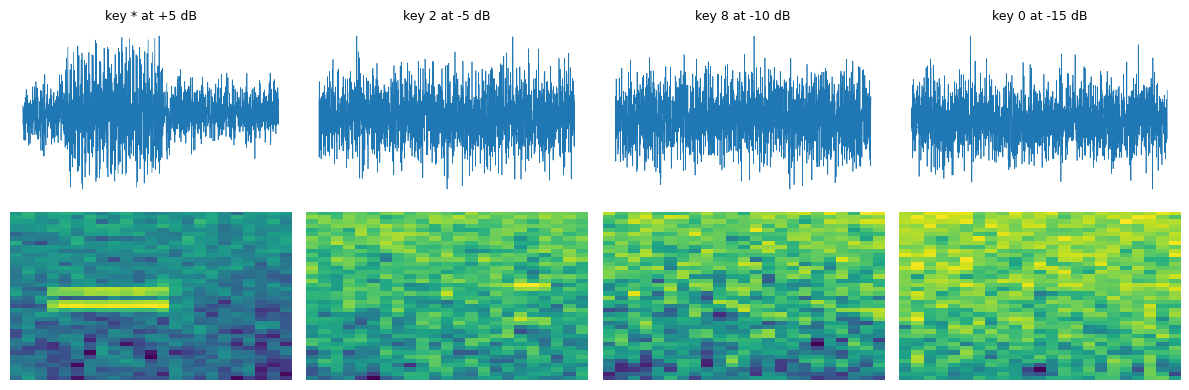

In [10]:
CLIP1 = 2000

def make_single(n, rng, snr_db=None, sr=SR):
    """n clips with one key each. Returns waves (n, 2000), key numbers (n,), SNRs in dB (n,)."""
    X = np.zeros((n, CLIP1)); y = rng.integers(0, 12, n)
    snr = rng.uniform(-15, 0, n) if snr_db is None else np.full(n, float(snr_db))
    for i in range(n):
        length = int(rng.integers(320, 801)); start = int(rng.integers(0, CLIP1 - length + 1))
        amp = rng.uniform(0.5, 1.0)
        X[i, start:start + length] = amp * key_tone(y[i], length, rng, sr)
        X[i] += rng.normal(0.0, amp / np.sqrt(10 ** (snr[i] / 10)), CLIP1)
    return X, y, snr

t0 = time.time()
Xw_tr, y_tr, snr_tr = make_single(6000, rng)
F_tr = log_mel(Xw_tr)
MU, SD = float(F_tr.mean()), float(F_tr.std())            # ONE mean and ONE spread, from the training set
norm = lambda F: ((F - MU) / SD)[..., None]
X_tr = norm(F_tr)
print(f"made {len(Xw_tr):,} clips in {time.time() - t0:.1f}s | waves {Xw_tr.shape} -> pictures {X_tr.shape}")
print(f"numbers per clip: {CLIP1:,} samples -> {X_tr.shape[1]} x {X_tr.shape[2]} = {X_tr.shape[1] * X_tr.shape[2]}")

# how visible is a tone at -10 dB?
demo, yd, _ = make_single(200, np.random.default_rng(1), snr_db=-10)
P = spectrogram(demo) ** 2
tone_bin = np.array([round(key_freqs(k)[0] * NFFT / SR) for k in yd])
peak = P[np.arange(200), :, tone_bin].max(axis=1)         # the low tone's bin, in its best frame
typical = np.median(P[:, :, 80:], axis=(1, 2))            # bins above 2,500 Hz hold noise only
print(f"at -10 dB: the tone's bin is {np.median(peak / typical):.0f} times a typical noise bin "
      f"({10 * np.log10(np.median(peak / typical)):.0f} dB above it)")

fig, ax = plt.subplots(2, 4, figsize=(12, 4))
for j, s in enumerate([5, -5, -10, -15]):
    w, k, _ = make_single(1, np.random.default_rng(10 + j), snr_db=s)
    ax[0, j].plot(w[0], lw=0.5); ax[0, j].set_title(f"key {KEYS[k[0]]} at {s:+d} dB", fontsize=9); ax[0, j].axis("off")
    ax[1, j].imshow(log_mel(w)[0].T, origin="lower", aspect="auto"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

### Why we see this

Noise spreads its power evenly over all 129 frequency bins. A tone puts all of its power into one or two.
So a tone that is ten times weaker than the noise overall still stands well above the noise **in its own
bin**. This is why the spectrogram is such a good front end for anything tonal, and why the waveform plots
above look hopeless while the pictures under them do not. It also sets the price of a short tone: fewer
frames contain it, so there are fewer chances to see it.

Note the normalisation: one mean and one standard deviation, computed once from the training set and reused
for every clip ever after. Step 14 tests how far that can be trusted.

---
## Step 11 - A small CNN for a picture of sound

The input is a picture of shape `(23, 40, 1)`: 23 frames, 40 mel bands, one channel. Three convolutions,
two poolings, then the largest value of each feature map anywhere in the picture
(`GlobalMaxPooling2D`: "did this pattern appear at all?"), and a `Dense(12)`.

**Predict:** count the parameters before you run the cell. A `Conv2D` with `k × k` kernels has
`k · k · channels_in · filters + filters`.

In [11]:
def build_key_cnn():
    return keras.Sequential([
        layers.Input(shape=(23, N_MELS, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.MaxPooling2D((1, 2)),                      # halve the frequency axis, keep every frame
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.GlobalMaxPooling2D(),
        layers.Dense(12),                                 # 12 logits, one per key
    ], name="key_cnn")

key_cnn = build_key_cnn()
key_cnn.summary()
by_hand = (3 * 3 * 1 * 16 + 16) + (3 * 3 * 16 * 32 + 32) + (3 * 3 * 32 * 32 + 32) + (32 * 12 + 12)
print("by hand: 160 + 4,640 + 9,248 + 396 =", f"{by_hand:,}")
assert key_cnn.count_params() == by_hand == 14444

Model: "key_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 23, 40, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 20, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 23, 20, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 10, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │           396 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,444 (56.42 KB)

 Trainable params: 14,444 (56.42 KB)

 Non-trainable params: 0 (0.00 B)

by hand: 160 + 4,640 + 9,248 + 396 = 14,444


---
## Step 12 - Train it, and test it one noise level at a time

Ten passes over 6,000 clips. Then seven fresh test sets of 1,000 clips, each at a single SNR.

**Predict:** chance is 1 in 12, or 8.3%. Guess the accuracy at +5, -5, -10 and -15 dB. Is the fall gradual
or a cliff?

In [12]:
key_cnn.compile(optimizer=keras.optimizers.Adam(2e-3),
                loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
t0 = time.time()
hist = key_cnn.fit(X_tr, y_tr, epochs=10, batch_size=64, verbose=0, validation_split=0.1)
print(f"trained in {time.time() - t0:.0f}s | training accuracy {hist.history['accuracy'][-1]:.3f} "
      f"| validation {hist.history['val_accuracy'][-1]:.3f} (clips at -15 to 0 dB)")

SNRS = [5, 0, -5, -8, -10, -12, -15]
tests = {s: make_single(1000, np.random.default_rng(1000 + s), snr_db=s) for s in SNRS}
acc_by_snr = {}
print(f"\n{'SNR':>7} {'accuracy':>9}")
for s in SNRS:
    Xw, yt, _ = tests[s]
    pred = key_cnn.predict(norm(log_mel(Xw)), verbose=0).argmax(axis=1)
    acc_by_snr[s] = (pred == yt).mean(); tests[s] = (Xw, yt, pred)
    print(f"{s:>+5d} dB {100 * acc_by_snr[s]:>8.1f}%")
print("chance: 8.3%")

trained in 14s | training accuracy 0.828 | validation 0.778 (clips at -15 to 0 dB)



    SNR  accuracy


   +5 dB    100.0%


   +0 dB    100.0%


   -5 dB     99.1%


   -8 dB     91.0%


  -10 dB     71.8%


  -12 dB     44.8%


  -15 dB     17.6%
chance: 8.3%


### Why we see this

It is a cliff, not a slope. Down to about -5 dB the two stripes are clearly above the noise in at least a
few frames and the answer is nearly always right. A few decibels lower the stripes sink into the noise
floor and accuracy drops towards chance. Detection problems often look like this: there is a threshold,
and most of the interesting behaviour happens within a few decibels of it.

The overall validation accuracy is an average over clips from -15 to 0 dB and hides the cliff completely.
**One accuracy number for a noisy task tells you about the mix of noise levels in the test set.**

---
## Step 13 - Read the mistakes

A wrong answer can still have one of the two tones right: the right row (the low tone) or the right column
(the high tone). If the network guessed blindly among the 11 wrong keys, 2 of them would share the row and
3 would share the column, so 5 in 11, or 45%, of blind mistakes would be half right.

**Predict:** at -10 dB, what share of the mistakes have one tone right? More or less than 45%?

  -8 dB:   90 wrong | right row  32 | right column  40 | one tone right in 80% of mistakes (blind guessing: 45%)
 -10 dB:  282 wrong | right row 103 | right column 110 | one tone right in 76% of mistakes (blind guessing: 45%)
 -12 dB:  552 wrong | right row 172 | right column 196 | one tone right in 67% of mistakes (blind guessing: 45%)
 -15 dB:  824 wrong | right row 193 | right column 234 | one tone right in 52% of mistakes (blind guessing: 45%)


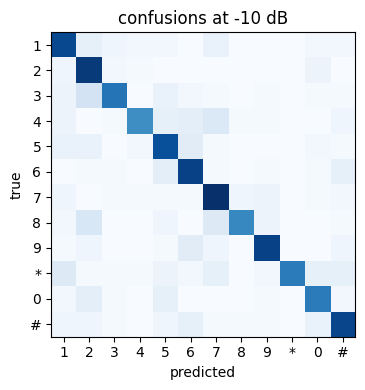

In [13]:
for s in [-8, -10, -12, -15]:
    _, yt, pred = tests[s]
    wrong = pred != yt
    same_row = wrong & (pred // 3 == yt // 3); same_col = wrong & (pred % 3 == yt % 3)
    half = (same_row | same_col).sum() / max(1, wrong.sum())
    print(f"{s:>+4d} dB: {wrong.sum():>4} wrong | right row {same_row.sum():>3} | right column {same_col.sum():>3} "
          f"| one tone right in {100 * half:.0f}% of mistakes (blind guessing: 45%)")

_, yt, pred = tests[-10]
conf = np.zeros((12, 12), int)
np.add.at(conf, (yt, pred), 1)
plt.figure(figsize=(4.6, 4)); plt.imshow(conf, cmap="Blues")
plt.xticks(range(12), list(KEYS)); plt.yticks(range(12), list(KEYS))
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("confusions at -10 dB"); plt.tight_layout(); plt.show()

### Why we see this

Near the cliff the mistakes are far from blind: most of them keep one tone and lose the other. The network
hears each of the two tones separately, and noise drowns one before the other. As the noise grows further,
both go and the share falls back towards the 45% of blind guessing. The confusion matrix shows it as
blocks of three (same row) and stripes four apart (same column). A speech recogniser's errors have the same
character: it confuses sounds that share most of their features, "bat" with "pat", not "bat" with "moon".

---
## Step 14 - Four ways to break it without touching the model, and one borrowed trick

The model is fine. Now serve it badly, on easy clips (0 dB, where it scores about 100%).

1. **Wrong sampling rate.** The clips come from a device that records at 16,000 samples a second, and
   nobody resamples them. Our pipeline believes every list is 8,000 a second.
2. **A quieter microphone.** The same clips, 20 times smaller in amplitude (26 dB quieter). Noise and tone
   shrink together, so the SNR is unchanged and the clip sounds the same, only softer.
3. **Clipping.** The recorder's input was set too high and every sample beyond ±0.3 is cut flat.
4. **No log.** The serving code computes mel energies and forgets the logarithm.

And a trick borrowed from photographs, where a mirrored cat is still a cat: **flip the picture**, left to
right (time runs backwards) or upside down (high pitch becomes low).

**Predict:** which of the four send the model to chance (8.3%)? Which does it survive? And which flip is
harmless?

In [14]:
def accuracy(pictures, labels):
    return 100 * (key_cnn.predict(pictures, verbose=0).argmax(axis=1) == labels).mean()

per_clip = lambda F: ((F - F.mean(axis=(1, 2), keepdims=True)) / F.std(axis=(1, 2), keepdims=True))[..., None]
Xw, yt, _ = make_single(1000, np.random.default_rng(77), snr_db=0)
F = log_mel(Xw)
print(f"served correctly                           : {accuracy(norm(F), yt):5.1f}%")

Xw16, yt16, _ = make_single(1000, np.random.default_rng(77), snr_db=0, sr=16000)
print(f"1. 16 kHz audio read as 8 kHz              : {accuracy(norm(log_mel(Xw16)), yt16):5.1f}%")
f16 = spectrogram(key_tone(4, 800, np.random.default_rng(0), sr=16000)).mean(axis=0)
print(f"      key 5 (770 + 1336 Hz) now peaks at {f16[:17].argmax() * SR / NFFT:.0f} and {(17 + f16[17:].argmax()) * SR / NFFT:.0f} Hz")

F_quiet = log_mel(0.05 * Xw)
print(f"2. microphone 20 times quieter             : {accuracy(norm(F_quiet), yt):5.1f}%")
print(f"      mean of the pictures: training set {MU:.2f}, these clips {F.mean():.2f}, the quiet ones {F_quiet.mean():.2f}"
      f" (training spread {SD:.2f})")
print(f"      the quiet clips, each normalised by itself: {accuracy(per_clip(F_quiet), yt):5.1f}%"
      f" | the normal clips, same treatment: {accuracy(per_clip(F), yt):5.1f}%")

print(f"3. clipped at ±0.3                         : {accuracy(norm(log_mel(np.clip(Xw, -0.3, 0.3))), yt):5.1f}%")

no_log = (spectrogram(Xw) ** 2 @ BANK.T).astype("float32")
print(f"4. no log                                  : {accuracy(norm(no_log), yt):5.1f}%")

print(f"\nflipped left to right (time reversed)      : {accuracy(norm(F[:, ::-1]), yt):5.1f}%")
print(f"flipped upside down (pitch reversed)       : {accuracy(norm(F[:, :, ::-1]), yt):5.1f}%")

served correctly                           :  99.9%


1. 16 kHz audio read as 8 kHz              :  13.1%
      key 5 (770 + 1336 Hz) now peaks at 375 and 656 Hz


2. microphone 20 times quieter             :   7.8%
      mean of the pictures: training set 6.18, these clips 4.56, the quiet ones -1.42 (training spread 1.46)


      the quiet clips, each normalised by itself: 100.0% | the normal clips, same treatment: 100.0%


3. clipped at ±0.3                         :  60.2%


4. no log                                  :  99.3%



flipped left to right (time reversed)      :  99.9%


flipped upside down (pitch reversed)       :  23.1%


### Why we see this

**Wrong rate.** A 770 Hz tone recorded at 16,000 samples a second completes a cycle every 20.8 samples. Read
as 8,000 a second, that is 385 Hz. Every frequency is halved: the whole sound is an octave lower, and no key
lives there. The model does not complain. It answers, with a key.

**A quieter microphone** is the one that surprises people. To the ear nothing changed. But the log turns a
gain into an **offset**: 20 times less amplitude is 400 times less power, and ln 400 = 6.0 is subtracted
from every cell of the picture (a little less where the small constant inside the log takes over). Measured
in training-set spreads that is a shift of several units, into a region of input space the network never
visited. The model was trained with one fixed mean, and all its training clips had about the same loudness.
Normalising each clip by its own mean and spread removes the offset: look at what that line printed.
Either choice can be right. What matters is that training and serving make the **same** choice, and that
training has seen the range of loudness that serving will bring.

**Clipping** flattens the peaks. A flattened wave contains new frequencies that were never in the sound
(multiples and mixtures of the originals), and they land in the picture as extra stripes.

**No log** does little damage on these loud, clean clips: the two stripes are still the largest thing in
the picture and the network's max-pooling finds them. Do not rely on that. The log matters most where
loudness varies and where the interesting parts are quiet, which is all real audio.

None of these raises an error. All four are found by looking at a spectrogram of what the model actually
received, next to one from the training set.

**The flips.** A steady tone played backwards is the same steady tone, so reversing time costs nothing
here. Reversing pitch moves every stripe to a band where no key lives. The two axes of this picture are
not interchangeable the way the two axes of a photograph are: across is *when*, up is *what*. (For speech
neither flip is safe: a word played backwards is not a word.)

---
## Step 15 - Task 2 data: a string of keys

Now the real problem of speech recognition, in miniature. A clip of 1.2 seconds contains **1 to 6 keys**.
Each tone lasts 40 to 90 ms; the silences between them last 30 to 80 ms; the string starts anywhere. The
label is only the string, for example `4 4 7 #`. **Nothing says where each key is.**

The SNR is drawn between -12 and +3 dB (against the tones while they sound).

**Predict:** the picture will have 118 frames. Why can we not train a classifier with one label per frame?

made 7,000 clips in 19s | waves (5000, 9600) -> pictures (5000, 118, 40, 1)
mean string length 3.51 keys | keys in the test set: 6,958
   clip 0: '6769' at -3 dB, tones at samples [(3450, 3862), (4285, 4967), (5499, 6016), (6430, 6915)]
   clip 1: '3' at +1 dB, tones at samples [(285, 678)]
   clip 2: '2414' at -0 dB, tones at samples [(610, 1113), (1656, 2082), (2460, 2893), (3244, 3862)]
   clip 3: '270519' at -9 dB, tones at samples [(2645, 3038), (3478, 4003), (4409, 4764), (5206, 5666), (6296, 6666), (7112, 7710)]


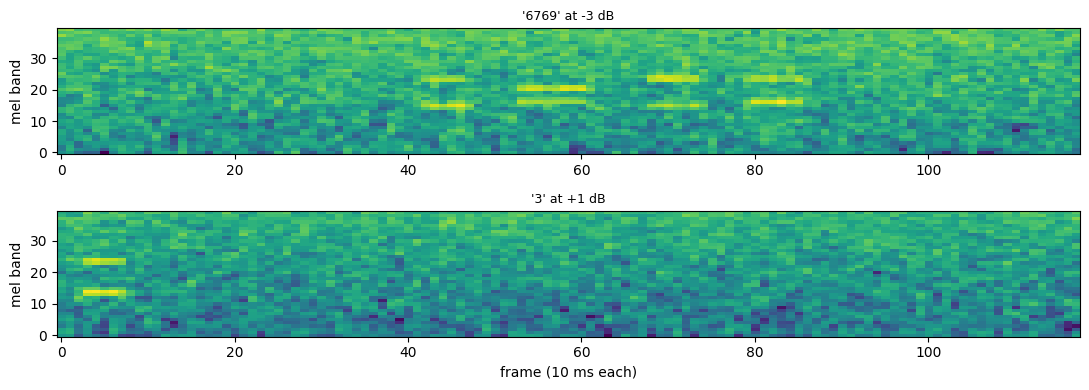

In [15]:
CLIP2, MAX_KEYS = 9600, 6

def make_strings(n, rng):
    """n clips, each a string of 1 to 6 keys. Labels are key number + 1 (0 is kept for CTC's blank)."""
    X = np.zeros((n, CLIP2)); Y = np.zeros((n, MAX_KEYS), "int32"); L = np.zeros(n, "int32")
    snr = rng.uniform(-12, 3, n); spans = []
    for i in range(n):
        while True:
            length = int(rng.integers(1, MAX_KEYS + 1))
            durs = rng.integers(320, 721, length); gaps = rng.integers(240, 641, length)
            total = int(durs.sum() + gaps[1:].sum())
            if total <= CLIP2 - 160:
                break
        pos = int(rng.integers(80, CLIP2 - total - 79))
        keys = rng.integers(0, 12, length); amp = rng.uniform(0.5, 1.0); sp = []
        for j in range(length):
            if j: pos += int(gaps[j])
            X[i, pos:pos + durs[j]] = amp * key_tone(keys[j], int(durs[j]), rng)
            sp.append((pos, pos + int(durs[j]))); pos += int(durs[j])
        X[i] += rng.normal(0.0, amp / np.sqrt(10 ** (snr[i] / 10)), CLIP2)
        Y[i, :length] = keys + 1; L[i] = length; spans.append(sp)
    return X, Y, L, snr, spans

text = lambda labels: "".join(KEYS[k - 1] for k in labels)
t0 = time.time()
Sw_tr, Ys_tr, Ls_tr, _, _ = make_strings(5000, rng)
Sw_te, Ys_te, Ls_te, snr_te, spans_te = make_strings(2000, np.random.default_rng(7))
Xs_tr, Xs_te = norm(log_mel(Sw_tr)), norm(log_mel(Sw_te))
print(f"made {len(Sw_tr) + len(Sw_te):,} clips in {time.time() - t0:.0f}s | waves {Sw_tr.shape} -> pictures {Xs_tr.shape}")
print(f"mean string length {Ls_tr.mean():.2f} keys | keys in the test set: {Ls_te.sum():,}")
for i in range(4):
    print(f"   clip {i}: '{text(Ys_te[i, :Ls_te[i]])}' at {snr_te[i]:+.0f} dB, tones at samples {spans_te[i]}")

fig, ax = plt.subplots(2, 1, figsize=(11, 4))
for r, i in enumerate([0, 1]):
    ax[r].imshow(Xs_te[i, :, :, 0].T, origin="lower", aspect="auto")
    ax[r].set_title(f"'{text(Ys_te[i, :Ls_te[i]])}' at {snr_te[i]:+.0f} dB", fontsize=9); ax[r].set_ylabel("mel band")
ax[1].set_xlabel("frame (10 ms each)"); plt.tight_layout(); plt.show()

### Why we see this

A per-frame classifier needs a label for each of the 118 frames, and we have a string of at most 6 symbols
with no timing. Somebody would have to mark where every key starts and stops. For real speech that means
marking the boundaries of every sound in thousands of hours of recordings, which nobody can afford and no
two people do alike. We need a loss that accepts "the string is `447#`" and works out the timing itself.

---
## Step 16 - CTC by hand: every alignment that collapses to the answer

**Connectionist temporal classification** (CTC, 2006) is that loss. The network outputs, at every frame, a
probability for each symbol plus one extra symbol, the **blank** (written `-`). A row of frame labels is
turned into a string by two rules, in this order:

1. merge repeats that touch: `-44--4-7` becomes `-4-4-7`
2. delete the blanks: `447`

Many rows collapse to the same string. CTC's probability of a string is the **sum** of the probabilities of
all the rows that collapse to it, and the loss is minus the log of that sum.

Small enough to do in full: 4 frames, symbols `a` and `b` plus blank, target `ab`.

**Predict:** there are 3⁴ = 81 possible rows. How many of them collapse to `ab`? (List a few first.)

In [16]:
def collapse(row, blank=0):
    """CTC's two rules: merge repeats that touch, then delete blanks."""
    out, prev = [], None
    for s in row:
        if s != prev and s != blank:
            out.append(int(s))
        prev = s
    return out

names = "-ab"
logits = np.random.default_rng(3).normal(size=(4, 3)).astype("float32")          # 4 frames, 3 symbols
probs = np.exp(logits) / np.exp(logits).sum(axis=1, keepdims=True)
target = [1, 2]                                                                  # "ab"
total, rows = 0.0, []
for row in itertools.product(range(3), repeat=4):                                # all 81 rows
    if collapse(row) == target:
        p = float(np.prod(probs[np.arange(4), row])); total += p
        rows.append(("".join(names[s] for s in row), p))
print(f"{len(rows)} of 81 rows collapse to 'ab':")
print("  ", "  ".join(f"{r} {p:.4f}" for r, p in rows))
print(f"sum of their probabilities {total:.5f} -> loss by hand {-np.log(total):.5f}")
ctc = lambda y, lg: keras.ops.ctc_loss(np.array([y], "int32"), lg[None], np.array([len(y)]),
                                       np.array([len(lg)]), mask_index=0).numpy()[0]
print(f"keras.ops.ctc_loss                         {ctc(target, logits):.5f}")
assert abs(ctc(target, logits) + np.log(total)) < 1e-4

print("\nCTC's two limits:")
print(f"  5 symbols 'ababa' from 4 frames -> loss {ctc([1, 2, 1, 2, 1], logits):.1f}")
print(f"  'aa' from 2 frames -> loss {ctc([1, 1], logits[:2]):.1f}   | 'aa' from 3 frames -> loss {ctc([1, 1], logits[:3]):.3f}")
print(f"  'ab' from 2 frames -> loss {ctc([1, 2], logits[:2]):.3f}")

15 of 81 rows collapse to 'ab':
   --ab 0.0033  -a-b 0.0006  -aab 0.0037  -ab- 0.0766  -abb 0.0019  a--b 0.0000  a-b- 0.0007  a-bb 0.0000  aa-b 0.0000  aaab 0.0000  aab- 0.0008  aabb 0.0000  ab-- 0.0003  abb- 0.0010  abbb 0.0000
sum of their probabilities 0.08888 -> loss by hand 2.42042


keras.ops.ctc_loss                         2.42042

CTC's two limits:
  5 symbols 'ababa' from 4 frames -> loss 707.7


  'aa' from 2 frames -> loss 707.6   | 'aa' from 3 frames -> loss 6.580
  'ab' from 2 frames -> loss 5.698


### Why we see this

The library's number matches the sum over the listed rows. (For 59 frames the rows are far too many to
list, and the library adds them up with dynamic programming, the same trick as the edit distance in
Step 20.) Every row is scored as a **product of per-frame probabilities**: CTC assumes that, given the
audio, each frame's label is independent of the others. That is the price of the simple sum.

Two limits follow from the collapse rules. The output can never be longer than the number of frames, so
no row of 4 frames collapses to 5 symbols: the probability is zero and the true loss is infinite. And a
doubled symbol needs a blank between its two copies, or rule 1 merges them: `aa` needs 3 frames (`a-a`),
where `ab` needs only 2. This implementation reports the impossible cases as a huge finite number (about
708) where others report `inf`. Either way, an absurd loss in CTC training nearly always means some clip is
too short for its label after the network's downsampling.

---
## Step 17 - The recogniser: a picture in, a row of frame labels out

The input is `(118, 40, 1)`. Two convolutions as before, pooling that halves the time axis once
(118 frames become 59, one every 20 ms), then each time step's column is flattened and passed through a
`Dense` layer and two `Conv1D` layers along time. The output is `(59, 13)`: for each of 59 frames, 13
logits (blank, then the 12 keys).

**Predict:** the longest label is 6 keys, at worst all the same. How many frames does CTC need for that,
and do 59 suffice? Then count the parameters.

In [17]:
T_IN = Xs_tr.shape[1]; T_OUT = T_IN // 2
assert (T_IN, T_OUT) == (118, 59)

def build_reader():
    inp = layers.Input(shape=(T_IN, N_MELS, 1))
    h = layers.Conv2D(16, 3, padding="same", activation="relu")(inp)
    h = layers.MaxPooling2D((1, 2))(h)                    # (118, 20, 16)
    h = layers.Conv2D(32, 3, padding="same", activation="relu")(h)
    h = layers.MaxPooling2D((2, 2))(h)                    # (59, 10, 32): time is halved here, once
    h = layers.Reshape((T_OUT, 10 * 32))(h)               # each time step: one column of 320 numbers
    h = layers.Dense(64, activation="relu")(h)
    h = layers.Conv1D(64, 5, padding="same", activation="relu")(h)
    h = layers.Conv1D(64, 5, padding="same", activation="relu")(h)
    return keras.Model(inp, layers.Dense(13)(h), name="reader")   # 13 = blank + 12 keys

reader = build_reader()
reader.summary()
by_hand = 160 + 4640 + (320 * 64 + 64) + 2 * (5 * 64 * 64 + 64) + (64 * 13 + 13)
print("by hand: 160 + 4,640 + 20,544 + 2 x 20,544 + 845 =", f"{by_hand:,}")
assert reader.count_params() == by_hand == 67277
print(f"frames needed for six identical keys: 6 + 5 blanks = 11; frames available: {T_OUT}")

Model: "reader"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 118, 40, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 118, 40, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 118, 20, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 118, 20, 32)    │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 59, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 59, 320)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 59, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 59, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 59, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 59, 13)         │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,277 (262.80 KB)

 Trainable params: 67,277 (262.80 KB)

 Non-trainable params: 0 (0.00 B)

by hand: 160 + 4,640 + 20,544 + 2 x 20,544 + 845 = 67,277
frames needed for six identical keys: 6 + 5 blanks = 11; frames available: 59


---
## Step 18 - Train with CTC

The training step is ordinary: run the model, compute the loss, apply the gradients. The only new line is
the loss, which takes the labels, the logits, the label lengths and the number of output frames.

After each pass we print the loss, the share of test frames whose most likely symbol is the blank, and the
share of test clips whose decoded string is exactly right (decoding is explained in the next step).

**Predict:** will the "exactly right" column rise smoothly from the first pass? Watch the blank column.

In [18]:
def greedy_decode(logits):
    """Best symbol per frame, then CTC's two rules. Returns the strings and the frame labels."""
    best = logits.argmax(axis=-1)
    return [collapse(row) for row in best], best

optimizer = keras.optimizers.Adam(3e-3)

@tf.function(autograph=False)                     # no Python branches inside, so nothing to convert
def train_step(x, y, y_len):
    with tf.GradientTape() as tape:
        logits = reader(x, training=True)
        frames_out = tf.fill([tf.shape(x)[0]], T_OUT)
        loss = tf.reduce_mean(keras.ops.ctc_loss(y, logits, y_len, frames_out, mask_index=0))
    grads = tape.gradient(loss, reader.trainable_variables)
    optimizer.apply_gradients(zip(grads, reader.trainable_variables))
    return loss

EPOCHS, BATCH = 14, 64
refs_te = [list(Ys_te[i, :Ls_te[i]]) for i in range(len(Ys_te))]
log = []
t0 = time.time()
print(f"{'pass':>4} {'CTC loss':>9} {'blank frames':>13} {'strings exactly right':>22} {'time':>6}")
for epoch in range(EPOCHS):
    order = np.random.default_rng(epoch).permutation(len(Xs_tr)); losses = []
    for b in range(0, len(order) - BATCH + 1, BATCH):
        i = order[b:b + BATCH]
        losses.append(float(train_step(Xs_tr[i], Ys_tr[i], Ls_tr[i])))
    hyp, best = greedy_decode(reader.predict(Xs_te[:500], verbose=0, batch_size=250))
    exact = np.mean([h == r for h, r in zip(hyp, refs_te[:500])])
    log.append((np.mean(losses), (best == 0).mean(), exact))
    print(f"{epoch + 1:>4} {log[-1][0]:>9.3f} {100 * log[-1][1]:>12.1f}% {100 * exact:>21.1f}% {time.time() - t0:>5.0f}s")

pass  CTC loss  blank frames  strings exactly right   time


   1    16.229        100.0%                   0.0%    10s


   2    10.727        100.0%                   0.0%    15s


   3    10.519        100.0%                   0.0%    21s


   4    10.450        100.0%                   0.0%    27s


   5    10.353        100.0%                   0.0%    33s


... (5 outputs left out)

  11     1.192         91.1%                  80.0%    69s


  12     1.180         91.0%                  80.6%    75s


  13     1.098         91.3%                  80.2%    80s


  14     1.038         91.0%                  80.6%    86s


### Why we see this

The first thing a CTC model learns is to say **blank everywhere**. Most frames really are blank, so
"always blank" is a cheap way to lower the loss a long way, and the network takes it. Then it sits on a
plateau, with the loss barely moving and every decoded string empty. Nothing is broken. The gradient is
quietly teaching a few frames that a key is worth a small bet; once some bets pay, the loss falls off the
plateau in a pass or two and the strings appear almost at once.

If you had stopped after three passes and concluded "CTC does not work on this", you would have been wrong by a few
passes. On a real recogniser the plateau can last hours.

---
## Step 19 - Greedy decoding, and what the alignments look like

Decoding is the collapse of Step 16 applied to the network's best guess at each frame: take the most
likely symbol per frame, merge touching repeats, delete blanks. Nothing was ever told where the keys are,
so let us look at where the network decided to put them.

Below, `truth` marks the 20 ms frames in which a tone really sounds, and `model` is the network's best
symbol per frame.

**Predict:** a tone lasts 2 to 5 output frames. Will the network label all of them with the key?

clip 0 at -3 dB
  truth : ---------------------666--77777---666---999----------------  '6769'
  model : ----------------------6-----77-----66----9-----------------  '6769'
clip 2 at -0 dB
  truth : ---2222---444--111--4444-----------------------------------  '2414'
  model : ----22-----4----1----44------------------------------------  '2414'
clip 3 at -9 dB
  truth : ----------------222--7777--00---555----11---9999-----------  '270519'
  model : -----------------2----77----0----55-----1-----9------------  '270519'
clip 5 at +1 dB
  truth : ---------000--999----8888--666---****----------------------  '0986*'
  model : ----------00---99-----88----66-----**----------------------  '0986*'

frames in which a tone sounds      : 19.1%
frames the model labels with a key : 8.6%
key labels per decoded key         : 1.51 frames
key labels that fall inside a tone : 98.7%


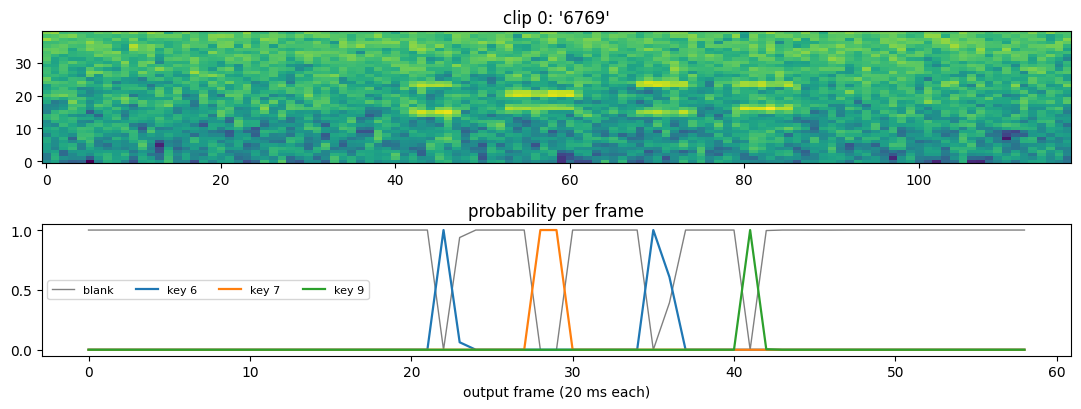

In [19]:
logits_te = reader.predict(Xs_te, verbose=0, batch_size=250)
hyp_te, best_te = greedy_decode(logits_te)

def truth_row(i):
    row = ["-"] * T_OUT
    for (a, b), k in zip(spans_te[i], refs_te[i]):
        for j in range(T_OUT):
            centre = (2 * j + 0.5) * HOP + FRAME / 2          # middle of output frame j, in samples
            if a <= centre < b:
                row[j] = KEYS[k - 1]
    return "".join(row)

shown = [i for i in range(60) if Ls_te[i] >= 4][:4]
for i in shown:
    print(f"clip {i} at {snr_te[i]:+.0f} dB")
    print("  truth :", truth_row(i), f" '{text(refs_te[i])}'")
    print("  model :", "".join("-" if s == 0 else KEYS[s - 1] for s in best_te[i]), f" '{text(hyp_te[i])}'")

on = np.array([[c != "-" for c in truth_row(i)] for i in range(len(refs_te))])
said = best_te != 0
print(f"\nframes in which a tone sounds      : {100 * on.mean():.1f}%")
print(f"frames the model labels with a key : {100 * said.mean():.1f}%")
print(f"key labels per decoded key         : {said.sum() / max(1, sum(len(h) for h in hyp_te)):.2f} frames")
print(f"key labels that fall inside a tone : {100 * (said & on).sum() / said.sum():.1f}%")

i = shown[0]
p = np.exp(logits_te[i]) / np.exp(logits_te[i]).sum(axis=1, keepdims=True)
fig, ax = plt.subplots(2, 1, figsize=(11, 4.2), sharex=False)
ax[0].imshow(Xs_te[i, :, :, 0].T, origin="lower", aspect="auto"); ax[0].set_title(f"clip {i}: '{text(refs_te[i])}'")
ax[1].plot(p[:, 0], color="grey", lw=1, label="blank")
for k in sorted(set(refs_te[i])): ax[1].plot(p[:, k], lw=1.6, label=f"key {KEYS[k - 1]}")
ax[1].legend(ncol=6, fontsize=8); ax[1].set_xlabel("output frame (20 ms each)"); ax[1].set_title("probability per frame")
plt.tight_layout(); plt.show()

### Why we see this

The model does not paint the whole tone. It emits a short **spike**, often a single frame, and says blank
for the rest, even while the tone is still sounding. CTC only rewards getting the string right, and one
confident frame per symbol is the cheapest way to do that: every extra frame is another chance to be wrong.
The spikes do land inside the tones, so the alignment was learnt without ever being given. But a CTC model's
frame labels are not a faithful record of when each sound starts and stops. If you need accurate timings,
CTC spikes are a rough guide and not a measurement.

---
## Step 20 - Scoring strings: the edit distance

For single keys, accuracy was enough. For strings we count the smallest number of edits that turn the
model's string into the true one. Three kinds: a **substitution** (wrong symbol), a **deletion** (a symbol
missing) and an **insertion** (an extra symbol).

**error rate = (substitutions + deletions + insertions) / symbols in the reference**

With words as the symbols this is the **word error rate** (WER) of speech recognition. First a sentence by
hand, then the test set.

**Predict:** reference "please call me at nine tomorrow morning", output "please call me a nine to morrow
morning". How many errors of each kind, and what is the WER?

In [20]:
def edit_ops(ref, hyp):
    """Smallest set of edits turning hyp into ref. Returns (S, D, I, list of (kind, ref index, hyp index))."""
    R, H = len(ref), len(hyp)
    d = np.zeros((R + 1, H + 1), int); d[:, 0] = np.arange(R + 1); d[0] = np.arange(H + 1)
    for i in range(1, R + 1):
        for j in range(1, H + 1):
            d[i, j] = min(d[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]), d[i - 1, j] + 1, d[i, j - 1] + 1)
    i, j, ops = R, H, []
    while i or j:
        if i and j and d[i, j] == d[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            if ref[i - 1] != hyp[j - 1]: ops.append(("S", i - 1, j - 1))
            i -= 1; j -= 1
        elif i and d[i, j] == d[i - 1, j] + 1:
            ops.append(("D", i - 1, None)); i -= 1
        else:
            ops.append(("I", None, j - 1)); j -= 1
    kinds = [o[0] for o in ops]
    return kinds.count("S"), kinds.count("D"), kinds.count("I"), ops

ref = "please call me at nine tomorrow morning".split()
hyp = "please call me a nine to morrow morning".split()
S, D, I, ops = edit_ops(ref, hyp)
print(f"reference {len(ref)} words | substitutions {S}, deletions {D}, insertions {I} "
      f"-> WER = {S + D + I}/{len(ref)} = {100 * (S + D + I) / len(ref):.1f}%")
S, D, I, _ = edit_ops("a b".split(), "a x y z b c".split())
print(f"a 2-word reference with 4 insertions: WER = {S + D + I}/2 = {100 * (S + D + I) / 2:.0f}%  (WER can pass 100%)")

S = D = I = 0; all_ops = []
for r, h in zip(refs_te, hyp_te):
    s, d_, i_, ops = edit_ops(r, h); S += s; D += d_; I += i_; all_ops.append(ops)
n_keys = int(Ls_te.sum())
exact_te = np.array([h == r for h, r in zip(hyp_te, refs_te)])
print(f"\ntest set: {len(refs_te):,} clips, {n_keys:,} keys")
print(f"strings exactly right : {100 * exact_te.mean():.1f}%   (string error rate {100 * (1 - exact_te.mean()):.1f}%)")
print(f"key error rate        : ({S} + {D} + {I}) / {n_keys:,} = {100 * (S + D + I) / n_keys:.2f}%")
print(f"   substitutions {S} ({100 * S / (S + D + I):.0f}%) | deletions {D} ({100 * D / (S + D + I):.0f}%) "
      f"| insertions {I} ({100 * I / (S + D + I):.0f}%)")

reference 7 words | substitutions 2, deletions 0, insertions 1 -> WER = 3/7 = 42.9%
a 2-word reference with 4 insertions: WER = 4/2 = 200%  (WER can pass 100%)

test set: 2,000 clips, 6,958 keys
strings exactly right : 79.5%   (string error rate 20.6%)
key error rate        : (223 + 361 + 90) / 6,958 = 9.69%
   substitutions 223 (33%) | deletions 361 (54%) | insertions 90 (13%)


### Why we see this

The sentence has 7 words and 3 errors: "at" became "a" (a substitution), and "tomorrow" came out as two
words, which the count sees as one substitution and one insertion. WER 3/7 = 42.9% for a transcript any
reader would understand. That is the first thing to know about WER: it counts edits, and it does not know
which edits matter. The second is that it has no ceiling: enough insertions push it past 100%.

The string error rate is much higher than the key error rate, as it must be: a string of six keys is wrong
if **any** of the six is wrong. Report both, and say which one you mean.

---
## Step 21 - Who gets hurt: the anatomy of CTC's mistakes

The total says how many errors. Now ask where they are: at which noise levels, in which string lengths,
and which keys are the ones that vanish.

**Predict:** deletions are the commonest error. Which tones get deleted: long ones or short ones? And when
the model substitutes one key for another, does it keep one of the two tones?

In [21]:
print("by noise level:")
for lo, hi in [(-12, -9), (-9, -6), (-6, -3), (-3, 0), (0, 3)]:
    m = (snr_te >= lo) & (snr_te < hi)
    errs = sum(len(all_ops[i]) for i in np.where(m)[0])
    print(f"  {lo:>+4d} to {hi:>+3d} dB: {m.sum():>4} clips | exactly right {100 * exact_te[m].mean():5.1f}% "
          f"| key error rate {100 * errs / Ls_te[m].sum():5.1f}%")
print("by string length:")
for n in range(1, MAX_KEYS + 1):
    m = Ls_te == n
    print(f"  {n} keys: {m.sum():>4} clips | exactly right {100 * exact_te[m].mean():5.1f}%")

dur_all, dur_del, sub_half, sub_n = [], [], 0, 0
for i, ops in enumerate(all_ops):
    dur_all += [(b - a) / SR * 1000 for a, b in spans_te[i]]
    for kind, ri, hi_ in ops:
        if kind == "D":
            a, b = spans_te[i][ri]; dur_del.append((b - a) / SR * 1000)
        if kind == "S":
            t, g = refs_te[i][ri] - 1, hyp_te[i][hi_] - 1
            sub_n += 1; sub_half += (t // 3 == g // 3) or (t % 3 == g % 3)
print(f"\nmean tone length: all keys {np.mean(dur_all):.0f} ms | deleted keys {np.mean(dur_del):.0f} ms")
short = np.array(dur_all) < 55
n_short_del = (np.array(dur_del) < 55).sum()
print(f"keys shorter than 55 ms: {100 * short.mean():.0f}% of all keys, {100 * n_short_del / len(dur_del):.0f}% of deleted keys")
print(f"substitutions that keep one of the two tones: {sub_half} of {sub_n} ({100 * sub_half / max(1, sub_n):.0f}%; blind: 45%)")

empty = np.array([len(h) == 0 for h in hyp_te])
has_double = np.array([any(a == b for a, b in zip(r[:-1], r[1:])) for r in refs_te])
multi = Ls_te >= 2
print(f"clips decoded as an empty string: {empty.sum()} of {len(hyp_te):,}")
print(f"strings with a doubled key (like '55'): {has_double.sum()} | exactly right {100 * exact_te[has_double].mean():.1f}% "
      f"| other strings of 2+ keys: {100 * exact_te[multi & ~has_double].mean():.1f}%")
print(f"\nwhole notebook: {time.time() - t_start:.0f}s")

by noise level:
   -12 to  -9 dB:  394 clips | exactly right  24.1% | key error rate  38.1%
    -9 to  -6 dB:  416 clips | exactly right  76.2% | key error rate   7.8%
    -6 to  -3 dB:  393 clips | exactly right  96.9% | key error rate   0.9%
    -3 to  +0 dB:  392 clips | exactly right  99.7% | key error rate   0.1%
    +0 to  +3 dB:  405 clips | exactly right 100.0% | key error rate   0.0%
by string length:
  1 keys:  313 clips | exactly right  88.5%
  2 keys:  352 clips | exactly right  82.4%
  3 keys:  362 clips | exactly right  77.3%
  4 keys:  321 clips | exactly right  81.0%
  5 keys:  341 clips | exactly right  74.2%
  6 keys:  311 clips | exactly right  73.6%

mean tone length: all keys 65 ms | deleted keys 59 ms
keys shorter than 55 ms: 30% of all keys, 47% of deleted keys
substitutions that keep one of the two tones: 181 of 223 (81%; blind: 45%)
clips decoded as an empty string: 23 of 2,000
strings with a doubled key (like '55'): 345 | exactly right 75.7% | other strings of

### Why we see this

The errors are not spread evenly. They pile up in the noisiest clips, and in the shortest tones: a tone
that lasts 40 ms is fully inside only one or two frames, so one burst of noise can hide it. When the model
is unsure whether something is there, saying blank is the safe bet, which is why **deletions lead**. A CTC
model in trouble goes quiet. Substitutions mostly keep one tone, as in Step 13. Insertions are the rarest:
the model seldom hears a key in pure noise.

Remember what Step 16 said about doubled symbols: `55` needs a blank between the two spikes. Compare the
two percentages on the last line and decide whether doubles were harder here. In this lab every pair of
tones is separated by at least 30 ms of silence, which gives the blank somewhere to live. In fast speech,
doubled letters have no such gap, and merging them is a classic CTC error.

A full-size speech recogniser fails in the same directions for the same reasons: more noise, shorter and
weaker sounds, and (for models that write text freely, unlike CTC) the opposite failure of inventing words
in silence. Its numbers will be nothing like these. The shape of the analysis is the same: never stop at
the average.

---
## Trials: change one thing at a time

Each trial changes one number or one line. Write your prediction first.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 6: `FRAME, HOP = 64, 32` (8 ms frames), then re-run from Step 8 | The rows are 73 Hz apart. What happens to the cliff in Step 12, and which tone (row or column) is lost first in Step 13? | |
| 2 | Step 8: `N_MELS = 12` (also change the `10 * 32` in Step 17 to `3 * 32`) | Which of the four row tones can still be told apart? | |
| 3 | Step 10: train only on clean clips, `snr = rng.uniform(5, 15, n)` | Where does the cliff of Step 12 move to? | |
| 4 | Step 14: build the 16 kHz clips, then keep every second sample (`Xw16[:, ::2]`, padded back to 2,000) | Does crude downsampling repair the rate mismatch? What would aliasing do if the audio had content above 4 kHz? | |
| 5 | Step 17: remove the two `Conv1D` layers | The model then sees each 20 ms step almost alone. Which error type grows? | |
| 6 | Step 18: `Adam(1e-3)` instead of `3e-3` | How long is the blank plateau now? | |
| 7 | Step 15: make the gaps shorter, `gaps = rng.integers(40, 161, length)` | What happens to strings with a doubled key? | |
| 8 | Step 17: pool time twice (a second `MaxPooling2D((2, 1))`, `T_OUT = 29`) | 6 keys need at most 11 frames, so the loss stays finite. Does accuracy survive? What about gaps of 30 ms? | |

## Exercises

1. **Augment the picture.** Before each training batch, set one random strip of 4 mel bands and one random
   strip of 5 frames to zero (the masking idea of SpecAugment, 2019). Does the error rate at the noisy end
   improve? Why must the frequency strip stay narrow for this task?
2. **A shift that changes the answer.** Roll the single-key test pictures up by one, two and four mel bands
   (`np.roll(F, k, axis=2)`) and plot accuracy against the shift. A CNN is built to tolerate shifts
   (Chapter 13). Why is that tolerance a problem on this axis, and useful on the time axis?
3. **Warm start.** The first two `Conv2D` layers of `reader` have the same shapes as those of `key_cnn`.
   Copy the trained weights across before Step 18. Does the blank plateau shorten?
4. **Beam search.** Greedy decoding picks the best symbol per frame. Write a decoder that keeps the 5 best
   partial strings per frame, adding up the probabilities of rows that collapse to the same string. On
   which clips does it change the answer?
5. **A recurrent reader.** Replace the two `Conv1D` layers by `Bidirectional(GRU(32, return_sequences=True))`
   (Chapter 20). Watch the plateau: you may need a different learning rate. Is the result worth the wait?
6. **Keyword spotting.** Turn task 2 into "does this clip contain the key `#`?" and train a classifier.
   Compare its miss rate with the rate at which the CTC reader deletes `#`.

## Cheat sheet

| Idea | One line |
|---|---|
| Sampling rate | numbers per second; it can hold frequencies up to half of itself |
| Aliasing | a frequency above that limit is recorded as a lower one, exactly and irreversibly |
| Spectrogram | frame, window, FFT, magnitude, log: time across, frequency up |
| Frame and hop | 25 ms every 10 ms is the usual choice for speech |
| Window trade | long frames separate close pitches, short frames separate close events; never both |
| Mel bands | triangular bands, narrow at low pitch and wide at high; 80 is common, 40 here |
| Normalisation | one mean and spread from the training set, reused at serving time |
| CTC output | one symbol or a blank per frame; merge touching repeats, then delete blanks |
| CTC loss | minus the log of the summed probability of every row that collapses to the label |
| CTC limits | label no longer than the frames; a doubled symbol needs a blank between; frames independent |
| Greedy decoding | best symbol per frame, then collapse |
| Error rate | (substitutions + deletions + insertions) / symbols in the reference |

```python
def log_mel(x):                                    # wave (n,) -> picture (frames, 40)
    idx = np.arange(200)[None, :] + 80 * np.arange(1 + (len(x) - 200) // 80)[:, None]
    mag = np.abs(np.fft.rfft(x[idx] * np.hanning(200), 256, axis=-1))
    return np.log(mag ** 2 @ BANK.T + 1e-3)

loss = keras.ops.ctc_loss(labels, logits, label_lengths, frame_counts, mask_index=0)
best = logits.argmax(axis=-1)                      # greedy: then merge repeats, drop blanks
```